# Ablação de minpts no CiteSeer — DensGNN × DeepDensGNN

Este notebook lê os `metrics.csv` de `results/minpts_citeseer/runs/` e associa cada linha ao
`metadata.yaml` da execução. O valor de `k` vem dos **parâmetros efetivamente registrados**,
não da ordem dos diretórios. Reexecute todas as células para atualizar a análise.

**Pergunta:** como qualidade, estabilidade, número de clusters e tempo mudam ao aumentar
`mrd_k = hdbscan_min_samples`, de 2 a 60, em passos de 2?

- Ambos os parâmetros variam juntos: esta é uma ablação conjunta; não isola o efeito causal de `mrd_k`.
- No DeepDensGNN, `mrd_k` participa da seleção adaptativa de suportes; a distância aprendida usa
  a mistura de `candidate_k`, mantida fixa nesta grade. Ver `models/DeepDensGNN/README.md`.
- As faixas representam **±1 desvio padrão amostral entre seeds** (`ddof=1`), não intervalos de confiança.
- Os melhores valores são descritivos nesta amostra; a escolha pelo melhor resultado observado
  não constitui validação independente nem teste de significância.

Dependências: `pandas`, `numpy`, `matplotlib`, `PyYAML` e um kernel Jupyter com `ipykernel`.
Não executa treinamento nem recalcula as métricas originais.

In [11]:
from pathlib import Path
from datetime import datetime, timezone
import json
import math
import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

%matplotlib inline

# Funciona a partir da raiz do repositório ou de scripts/.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'configs/densgnn_minpts_ablation_citeseer').is_dir()), None)
if ROOT is None:
    raise FileNotFoundError('Abra o notebook dentro do repositório NodeClusteringAlgorithms.')
RUNS_DIR = ROOT / 'results/minpts_citeseer/runs'
CONFIG_DIR = ROOT / 'configs/densgnn_minpts_ablation_citeseer'
EXPORT_DIR = ROOT / 'results/minpts_citeseer/analysis'
MODELS = ['densgnn', 'deep_densgnn']
K_VALUES = list(range(2, 61, 2))
LABELS = {'densgnn': 'DensGNN', 'deep_densgnn': 'DeepDensGNN'}
COLORS = {'densgnn': '#2563eb', 'deep_densgnn': '#e76f24'}
METRICS = ['acc', 'nmi', 'ari', 'f1_macro', 'f1_micro', 'modularity',
           'n_clusters', 'runtime_seconds', 'silhouette', 'calinski_harabasz', 'davies_bouldin']
TITLES = {'acc': 'ACC ↑', 'nmi': 'NMI ↑', 'ari': 'ARI ↑', 'f1_macro': 'F1 macro ↑',
          'f1_micro': 'F1 micro ↑', 'modularity': 'Modularidade ↑',
          'n_clusters': 'Número de clusters', 'runtime_seconds': 'Tempo (s) ↓',
          'silhouette': 'Silhouette ↑', 'calinski_harabasz': 'Calinski–Harabasz ↑',
          'davies_bouldin': 'Davies–Bouldin ↓'}
YAML_LOADER = getattr(yaml, 'CSafeLoader', yaml.SafeLoader)
pd.set_option('display.max_rows', 70)
pd.set_option('display.max_columns', 20)
pd.set_option('display.float_format', lambda x: f'{x:.4f}')
plt.rcParams.update({'figure.dpi': 115, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': .18})
figures = {}
print('Fonte:', RUNS_DIR)
print('Leitura em UTC:', datetime.now(timezone.utc).isoformat(timespec='seconds'))

Fonte: /home/gmessias/NodeClusteringAlgorithms/results/minpts_citeseer/runs
Leitura em UTC: 2026-09-30T19:13:04+00:00


## 1. Leitura e auditoria

Usamos apenas os CSVs de cada run, evitando duplicar linhas com o agregado do dataset.
Falhas, metadados ausentes e configurações diferentes das configs da ablação são exibidos e
excluídos dos resumos. Repetições bem-sucedidas do mesmo `(modelo, k, seed)` interrompem
 a análise para não dar peso extra a uma seed silenciosamente.

In [12]:
configs = {k: yaml.load((CONFIG_DIR / f'minpts_{k}.yaml').read_text(), Loader=YAML_LOADER)
           for k in K_VALUES}
rows, issues = [], []
run_dirs = sorted(p for p in RUNS_DIR.iterdir() if p.is_dir())
for run_dir in run_dirs:
    csv_path = run_dir / 'metrics.csv'
    if not csv_path.exists():
        issues.append({'run_id': run_dir.name, 'motivo': 'metrics.csv ausente (run incompleto?)'})
        continue
    try:
        frame = pd.read_csv(csv_path)
    except (pd.errors.EmptyDataError, pd.errors.ParserError) as exc:
        issues.append({'run_id': run_dir.name, 'motivo': str(exc)})
        continue
    for row in frame.to_dict('records'):
        if row.get('model') not in MODELS:
            continue
        model = row['model']
        row.update(csv_path=str(csv_path.relative_to(ROOT)), eligible=False)
        try:
            meta_path = run_dir / model / 'metadata.yaml'
            meta = yaml.load(meta_path.read_text(), Loader=YAML_LOADER)
            params = meta['model_params']
            k, min_samples = int(params['mrd_k']), int(params['hdbscan_min_samples'])
            row.update(mrd_k=k, hdbscan_min_samples=min_samples,
                       metadata_path=str(meta_path.relative_to(ROOT)),
                       data_pt=meta.get('data_pt'), device=meta.get('device'),
                       git_commit=meta.get('git_commit'), start_time=meta.get('start_time'),
                       internal_metrics_space=meta.get('internal_metrics_space'),
                       fixed_params=json.dumps({key: value for key, value in params.items()
                                                if key not in ['mrd_k', 'hdbscan_min_samples']}, sort_keys=True))
            reasons = []
            if row['run_id'] != run_dir.name or meta.get('model') != model or meta.get('seed') != row['seed']:
                reasons.append('identificação CSV/metadata inconsistente')
            if meta.get('status') != row.get('status'):
                reasons.append('status CSV/metadata inconsistente')
            if k not in configs or k != min_samples:
                reasons.append('parâmetros fora da grade mrd_k = min_samples de 2 a 60, em passos de 2')
            else:
                cfg = configs[k]
                if params != cfg['models'][model]['params']:
                    reasons.append('model_params diferentes da config da ablação')
                expected_data = (ROOT / cfg['experiment']['data_pt']).resolve()
                actual_data = (ROOT / meta['data_pt']).resolve()
                if actual_data != expected_data or row['dataset'] != cfg['experiment']['dataset']:
                    reasons.append('dataset diferente da config')
                if meta.get('device') != cfg['experiment']['device']:
                    reasons.append('device diferente da config')
            row['eligible'] = not reasons
            if reasons:
                issues.append({'run_id': run_dir.name, 'model': model, 'motivo': '; '.join(reasons)})
        except (OSError, yaml.YAMLError, KeyError, TypeError, ValueError) as exc:
            issues.append({'run_id': run_dir.name, 'model': model, 'motivo': str(exc)})
        rows.append(row)

raw = pd.DataFrame(rows)
if raw.empty:
    raise ValueError('Nenhuma execução dos modelos selecionados encontrada.')
for metric in METRICS:
    raw[metric] = pd.to_numeric(raw.get(metric, np.nan), errors='coerce').replace([np.inf, -np.inf], np.nan)
issues_df = pd.DataFrame(issues)
display(raw.groupby(['model', 'status'], dropna=False).size().rename('execuções').to_frame())
if not issues_df.empty:
    display(issues_df)
failed = raw.loc[raw.status.ne('success')]
if not failed.empty:
    display(failed.reindex(columns=['run_id', 'model', 'status', 'error']))

data = raw.loc[raw.eligible & raw.status.eq('success')].copy()
if data.empty:
    raise ValueError('Não há resultados elegíveis bem-sucedidos.')
data['mrd_k'] = data['mrd_k'].astype(int)
data['seed'] = data['seed'].astype(int)
duplicates = data[data.duplicated(['model', 'mrd_k', 'seed'], keep=False)]
if not duplicates.empty:
    display(duplicates[['run_id', 'model', 'mrd_k', 'seed']])
    raise ValueError('Há seeds repetidas para o mesmo modelo/k. Selecione explicitamente os runs antes de resumir.')
data = data.sort_values(['model', 'mrd_k', 'seed']).reset_index(drop=True)
print(f'{len(data)} execuções elegíveis; {data.run_id.nunique()} runs; seeds: {sorted(data.seed.unique())}')
display(data.groupby('model')[['fixed_params', 'device', 'data_pt', 'git_commit',
                              'internal_metrics_space']].nunique(dropna=False).rename_axis('valores distintos por modelo'))

,,execuções
model,status,
deep_densgnn,success,90
densgnn,success,90


180 execuções elegíveis; 90 runs; seeds: [np.int64(2026), np.int64(2027), np.int64(2028)]


,fixed_params,device,data_pt,git_commit,internal_metrics_space
valores distintos por modelo,,,,,
deep_densgnn,1,1,1,1,1
densgnn,1,1,1,1,1


In [13]:
# Cobertura real versus seeds previstas em cada YAML.
coverage_rows = []
for k, cfg in configs.items():
    exp = cfg['experiment']
    expected_seeds = set(range(exp['seed'], exp['seed'] + exp['runs']))
    for model in MODELS:
        subset = data[(data.model == model) & (data.mrd_k == k)]
        actual_seeds = set(subset.seed)
        coverage_rows.append({'mrd_k': k, 'model': model, 'n': len(subset),
                              'expected_n': len(expected_seeds),
                              'missing_seeds': sorted(expected_seeds - actual_seeds),
                              'extra_seeds': sorted(actual_seeds - expected_seeds)})
coverage = pd.DataFrame(coverage_rows)
display(coverage.pivot(index='mrd_k', columns='model', values='n'))
incomplete = coverage[coverage.apply(lambda r: bool(r.missing_seeds or r.extra_seeds), axis=1)]
if incomplete.empty:
    print('Grade completa: todas as seeds previstas estão presentes para ambos os modelos.')
else:
    display(incomplete)
missing_metrics = data[METRICS].isna().sum()
print('Métricas ausentes:', missing_metrics[missing_metrics > 0].to_dict() or 'nenhuma')

model,deep_densgnn,densgnn
mrd_k,,
2,3,3
4,3,3
6,3,3
8,3,3
10,3,3
12,3,3
14,3,3
16,3,3
18,3,3


Grade completa: todas as seeds previstas estão presentes para ambos os modelos.
Métricas ausentes: nenhuma


## 2. Média e desvio padrão

A tabela principal agrupa por **modelo e k**: cada desvio mede a variação entre seeds naquele ponto.
`count` é calculado por métrica, sem preencher valores ausentes com zero. Um único resultado tem
DP indefinido. O resumo global mistura valores de k e seeds; seu DP não é uma medida isolada
 de estabilidade entre seeds. Com a grade completa, cada k tem o mesmo peso no resumo global.

In [14]:
summary = data.groupby(['model', 'mrd_k'])[METRICS].agg(['mean', 'std', 'count'])
summary.columns.names = ['metric', 'statistic']
summary_long = data.melt(id_vars=['model', 'mrd_k', 'seed'], value_vars=METRICS,
                         var_name='metric', value_name='value').groupby(
                             ['model', 'mrd_k', 'metric'])['value'].agg(['mean', 'std', 'count']).reset_index()
global_summary = data.groupby('model')[METRICS].agg(['mean', 'std', 'count'])

def mean_std_table(frame, metrics):
    table = pd.DataFrame(index=frame.index)
    for metric in metrics:
        table[metric] = [f'{mean:.4f} ± {std:.4f} (n={int(n)})' if pd.notna(std)
                         else f'{mean:.4f} ± indefinido (n={int(n)})'
                         for mean, std, n in frame[metric][['mean', 'std', 'count']].itertuples(index=False, name=None)]
    return table

print('Resumo global — todos os k e seeds:')
display(mean_std_table(global_summary, ['acc', 'nmi', 'ari', 'modularity', 'runtime_seconds']))
print('Resumo por k — média ± DP entre seeds:')
display(mean_std_table(summary, ['acc', 'nmi', 'ari', 'modularity', 'n_clusters']))
# Todas as métricas, inclusive F1 e métricas internas, estão em summary e summary_long.

Resumo global — todos os k e seeds:


,acc,nmi,ari,modularity,runtime_seconds
model,,,,,
deep_densgnn,0.4532 ± 0.0887 (n=90),0.2578 ± 0.0591 (n=90),0.2152 ± 0.0666 (n=90),0.6117 ± 0.1096 (n=90),86.2783 ± 11.0437 (n=90)
densgnn,0.4542 ± 0.0876 (n=90),0.2574 ± 0.0597 (n=90),0.2158 ± 0.0678 (n=90),0.6209 ± 0.1157 (n=90),85.7854 ± 10.9158 (n=90)


Resumo por k — média ± DP entre seeds:


acc                    nmi  \
model        mrd_k                                                 
deep_densgnn 2      0.3779 ± 0.0313 (n=3)  0.2845 ± 0.0068 (n=3)   
             4      0.2864 ± 0.0565 (n=3)  0.2676 ± 0.0145 (n=3)   
             6      0.3381 ± 0.0517 (n=3)  0.2706 ± 0.0081 (n=3)   
             8      0.3258 ± 0.0189 (n=3)  0.2550 ± 0.0070 (n=3)   
             10     0.3612 ± 0.0681 (n=3)  0.2624 ± 0.0203 (n=3)   
             12     0.4142 ± 0.0475 (n=3)  0.2784 ± 0.0121 (n=3)   
             14     0.4129 ± 0.0542 (n=3)  0.2617 ± 0.0271 (n=3)   
             16     0.4135 ± 0.0325 (n=3)  0.2703 ± 0.0121 (n=3)   
             18     0.4750 ± 0.0863 (n=3)  0.2859 ± 0.0347 (n=3)   
             20     0.4369 ± 0.0797 (n=3)  0.2800 ± 0.0307 (n=3)   
             22     0.4585 ± 0.0192 (n=3)  0.2747 ± 0.0259 (n=3)   
             24     0.4853 ± 0.0598 (n=3)  0.2847 ± 0.0350 (n=3)   
             26     0.5105 ± 0.0525 (n=3)  0.2814 ± 0.0410 (n=3)   
             28     0.5072 ± 0.0324 (n=3)  0.2833 ± 0.0479 (n=3)   
             30     0.5259 ± 0.0445 (n=3)  0.2785 ± 0.0504 (n=3)   
             32     0.5226 ± 0.0546 (n=3)  0.2862 ± 0.0407 (n=3)   
             34     0.5186 ± 0.0787 (n=3)  0.2844 ± 0.0632 (n=3)   
             36     0.4966 ± 0.0494 (n=3)  0.2816 ± 0.0456 (n=3)   
             38     0.5413 ± 0.0237 (n=3)  0.2825 ± 0.0244 (n=3)   
             40     0.5044 ± 0.0121 (n=3)  0.2601 ± 0.0476 (n=3)   
             42     0.5192 ± 0.0441 (n=3)  0.2671 ± 0.0615 (n=3)   
             44     0.4906 ± 0.0305 (n=3)  0.2544 ± 0.0395 (n=3)   
             46     0.5060 ± 0.0445 (n=3)  0.2615 ± 0.0326 (n=3)   
             48     0.4758 ± 0.1346 (n=3)  0.2238 ± 0.1213 (n=3)   
             50     0.4593 ± 0.1200 (n=3)  0.2097 ± 0.1078 (n=3)   
             52     0.4683 ± 0.1283 (n=3)  0.2195 ± 0.1144 (n=3)   
             54     0.4647 ± 0.1260 (n=3)  0.2174 ± 0.1151 (n=3)   
             56     0.4677 ± 0.1258 (n=3)  0.2102 ± 0.1056 (n=3)   
             58     0.4154 ± 0.1134 (n=3)  0.1790 ± 0.0960 (n=3)   
             60     0.4155 ± 0.1127 (n=3)  0.1778 ± 0.0924 (n=3)   
densgnn      2      0.2950 ± 0.0917 (n=3)  0.2722 ± 0.0253 (n=3)   
             4      0.3642 ± 0.0565 (n=3)  0.2865 ± 0.0208 (n=3)   
             6      0.3427 ± 0.0988 (n=3)  0.2779 ± 0.0111 (n=3)   
             8      0.3326 ± 0.0328 (n=3)  0.2683 ± 0.0115 (n=3)   
             10     0.3977 ± 0.0621 (n=3)  0.2674 ± 0.0153 (n=3)   
             12     0.3922 ± 0.0185 (n=3)  0.2692 ± 0.0024 (n=3)   
             14     0.4073 ± 0.0462 (n=3)  0.2806 ± 0.0149 (n=3)   
             16     0.4518 ± 0.0375 (n=3)  0.2781 ± 0.0085 (n=3)   
             18     0.4736 ± 0.0604 (n=3)  0.2835 ± 0.0275 (n=3)   
             20     0.4673 ± 0.0842 (n=3)  0.2794 ± 0.0286 (n=3)   
             22     0.4814 ± 0.0499 (n=3)  0.2832 ± 0.0275 (n=3)   
             24     0.4831 ± 0.0319 (n=3)  0.2784 ± 0.0263 (n=3)   
             26     0.4963 ± 0.0249 (n=3)  0.2863 ± 0.0372 (n=3)   
             28     0.5099 ± 0.0404 (n=3)  0.2807 ± 0.0387 (n=3)   
             30     0.5141 ± 0.0439 (n=3)  0.2856 ± 0.0349 (n=3)   
             32     0.5217 ± 0.0315 (n=3)  0.2860 ± 0.0228 (n=3)   
             34     0.5327 ± 0.0576 (n=3)  0.2822 ± 0.0599 (n=3)   
             36     0.5102 ± 0.0467 (n=3)  0.2674 ± 0.0516 (n=3)   
             38     0.5298 ± 0.0153 (n=3)  0.2756 ± 0.0360 (n=3)   
             40     0.5126 ± 0.0265 (n=3)  0.2596 ± 0.0476 (n=3)   
             42     0.5088 ± 0.0912 (n=3)  0.2601 ± 0.0730 (n=3)   
             44     0.5085 ± 0.0470 (n=3)  0.2604 ± 0.0447 (n=3)   
             46     0.4994 ± 0.0827 (n=3)  0.2509 ± 0.0699 (n=3)   
             48     0.4640 ± 0.1241 (n=3)  0.2200 ± 0.1130 (n=3)   
             50     0.4633 ± 0.1226 (n=3)  0.2135 ± 0.1112 (n=3)   
             52     0.4187 ± 0.1015 (n=3)  0.1883 ± 0.0987 (n=3)   
             54     0.4598 ± 0.1224 (n=3)  0.2113 ± 0.1107 (n=3)   
             56     0.4611

## 3. Curvas da ablação

Linhas: média por k. Faixas: ±1 DP entre seeds. Pontos discretos: execuções individuais.
As faixas não são cortadas nos limites das métricas. Lacunas representam dados ausentes.
O eixo x sempre significa **mrd_k = hdbscan_min_samples**.

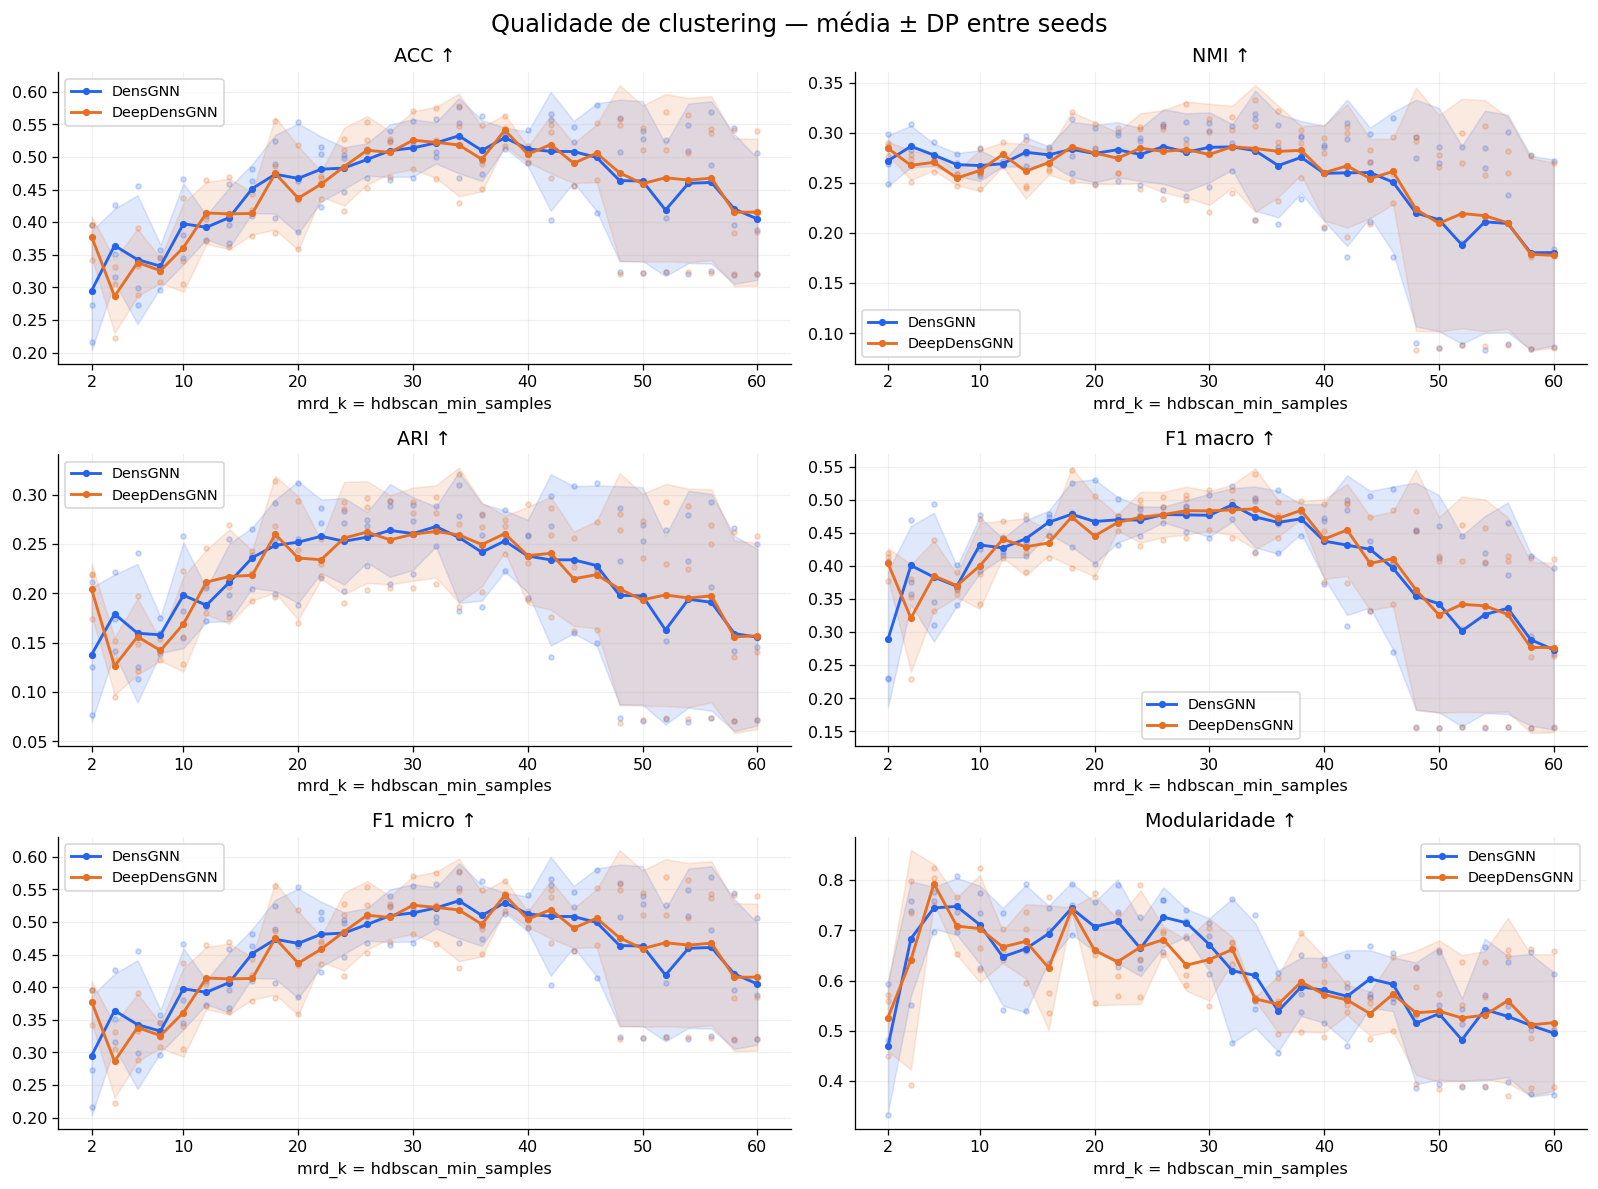

In [15]:
def plot_curves(metrics, title, key):
    fig, axes = plt.subplots(math.ceil(len(metrics) / 2), 2,
                             figsize=(14, 3.5 * math.ceil(len(metrics) / 2)), squeeze=False)
    for ax, metric in zip(axes.flat, metrics):
        for model in MODELS:
            stats = summary.loc[model, metric].reindex(K_VALUES)
            x = np.array(K_VALUES)
            mean, std = stats['mean'].to_numpy(float), stats['std'].to_numpy(float)
            ax.plot(x, mean, '-o', ms=3.5, lw=1.8, color=COLORS[model], label=LABELS[model])
            ax.fill_between(x, mean - std, mean + std, color=COLORS[model], alpha=.14)
            runs = data[data.model == model]
            ax.scatter(runs.mrd_k, runs[metric], s=10, alpha=.22, color=COLORS[model])
        ax.set(title=TITLES[metric], xlabel='mrd_k = hdbscan_min_samples')
        ax.set_xticks([2, 10, 20, 30, 40, 50, 60])
        ax.legend(fontsize=9)
    for ax in list(axes.flat)[len(metrics):]:
        ax.set_visible(False)
    fig.suptitle(title, fontsize=15)
    fig.tight_layout()
    figures[key] = fig
    plt.show()

plot_curves(['acc', 'nmi', 'ari', 'f1_macro', 'f1_micro', 'modularity'],
            'Qualidade de clustering — média ± DP entre seeds', 'quality_curves')

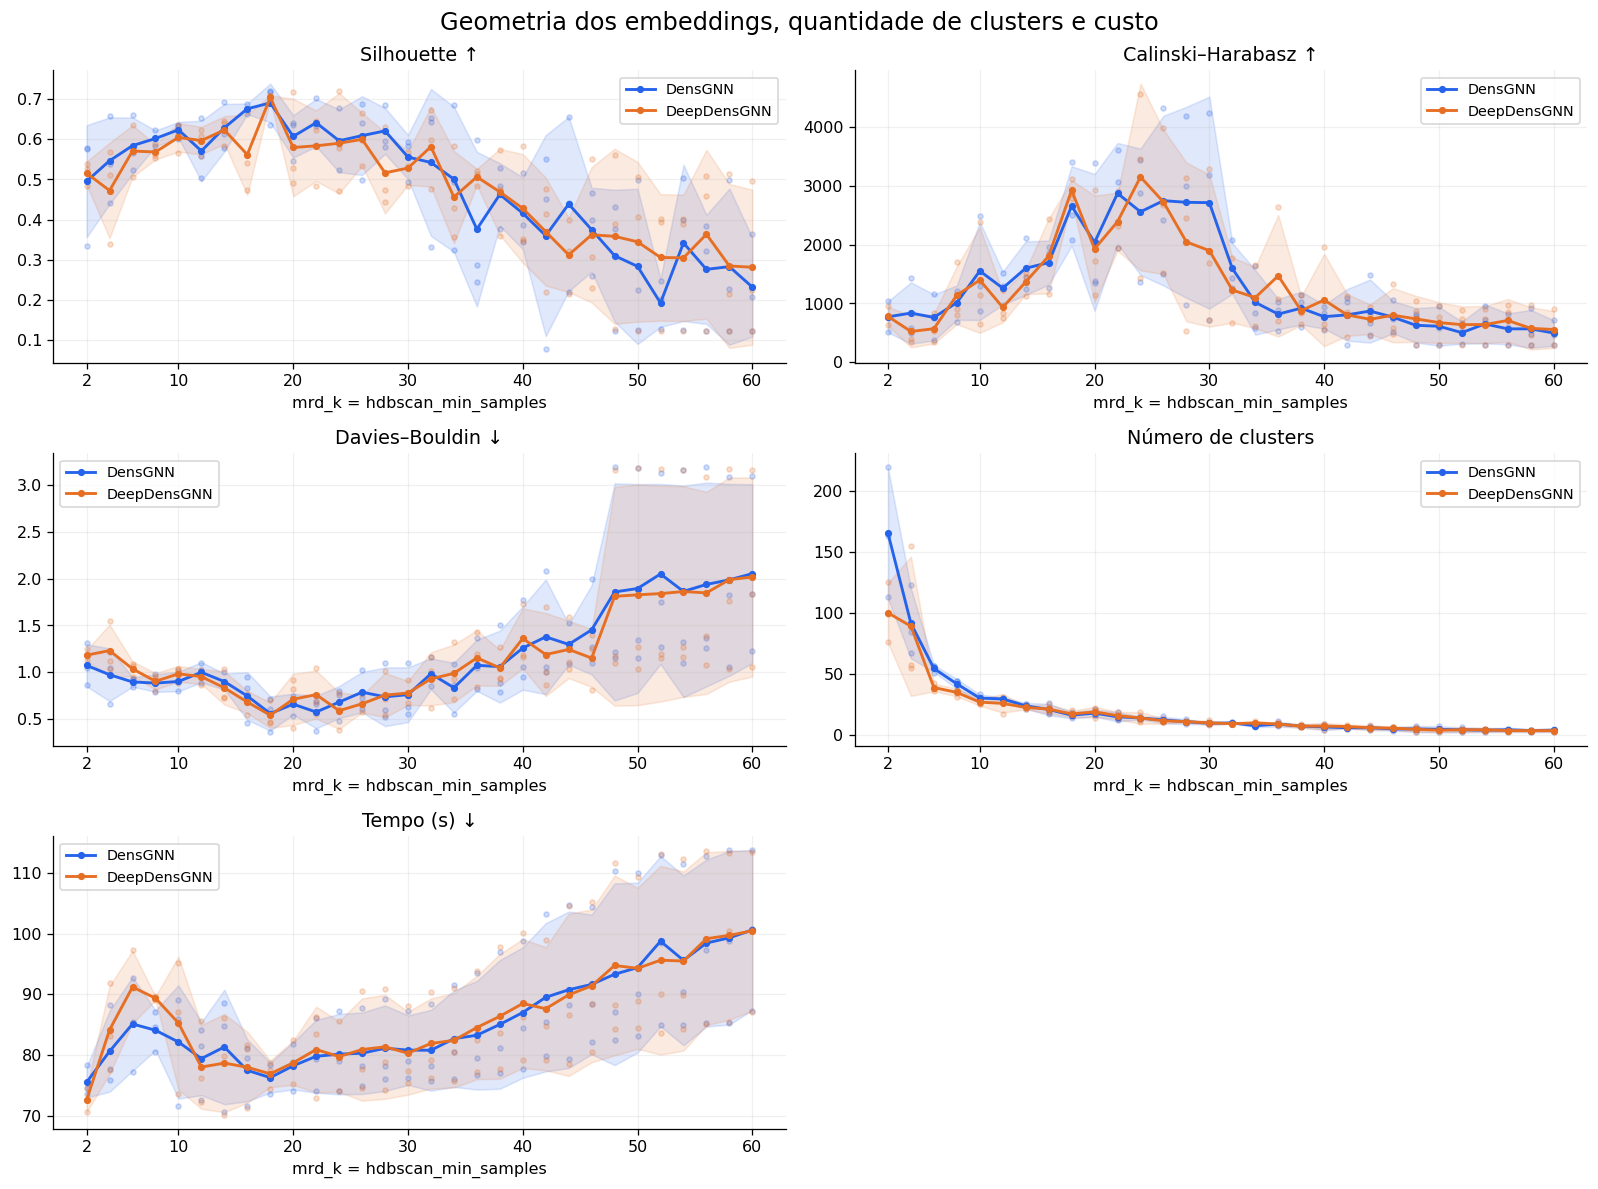

In [16]:
plot_curves(['silhouette', 'calinski_harabasz', 'davies_bouldin', 'n_clusters', 'runtime_seconds'],
            'Geometria dos embeddings, quantidade de clusters e custo', 'internal_runtime_curves')

Silhouette, Calinski–Harabasz e Davies–Bouldin descrevem o espaço registrado em
`internal_metrics_space` (nestas execuções, os embeddings de cada modelo).
Assim, embeddings diferentes também mudam essas métricas. Número de clusters é descritivo:
mais ou menos clusters não significa automaticamente melhor qualidade.

## 4. Curvas individuais por seed

Permitem observar se a tendência média aparece nas três seeds ou se depende de uma execução.
As linhas apenas conectam pontos observados; não representam ajuste de regressão.

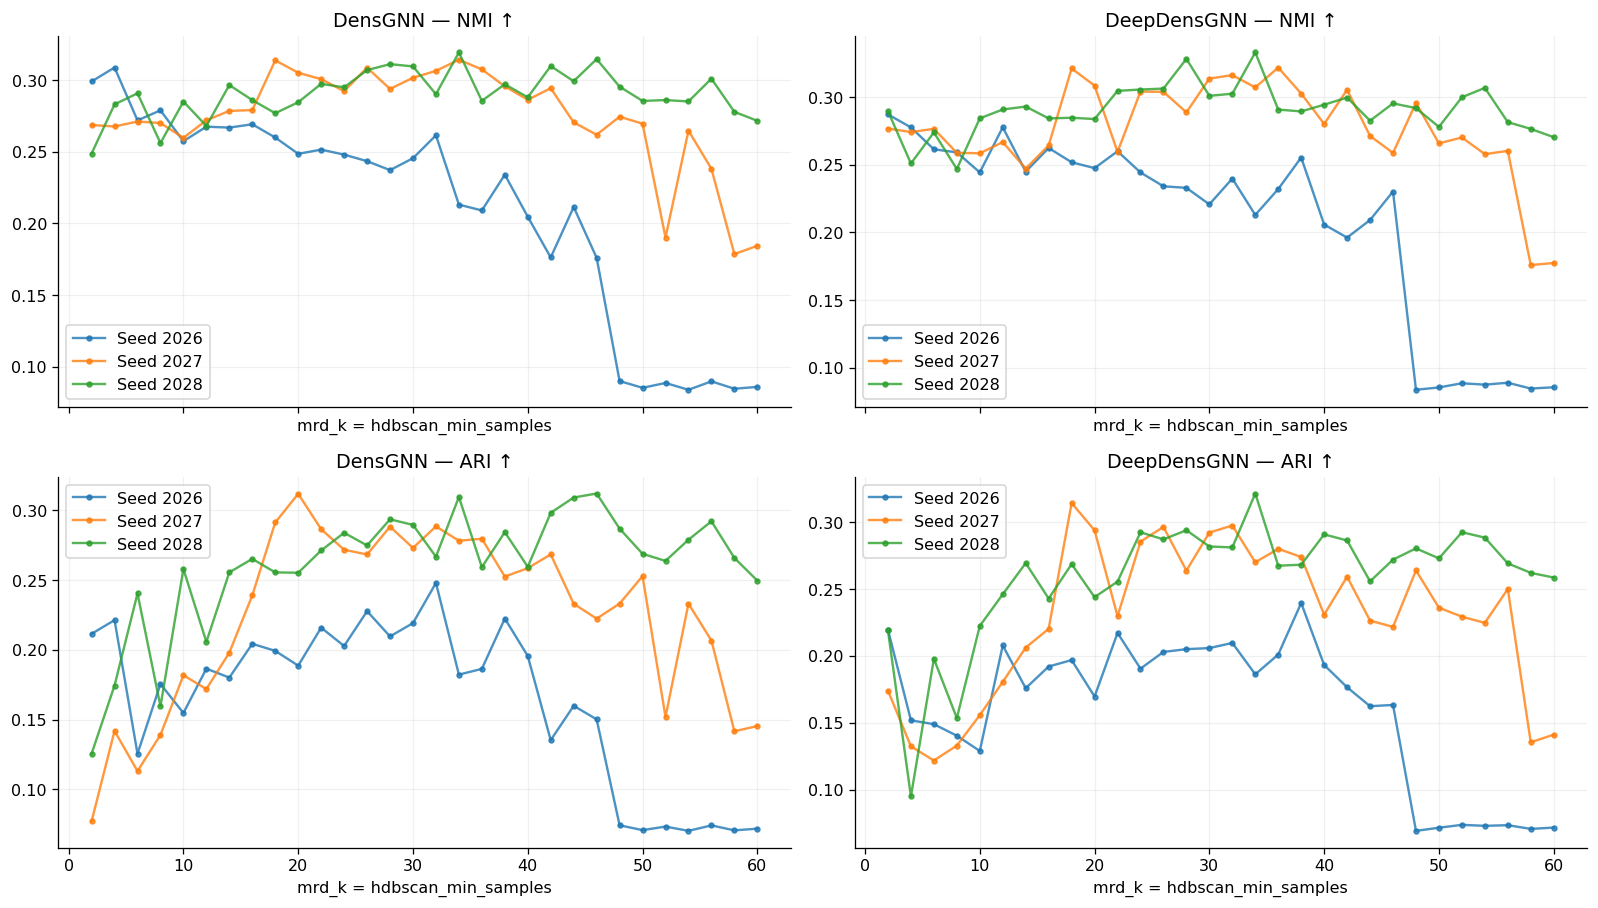

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True)
seed_colors = dict(zip(sorted(data.seed.unique()), plt.get_cmap('tab10').colors))
for col, model in enumerate(MODELS):
    for row, metric in enumerate(['nmi', 'ari']):
        ax = axes[row, col]
        for seed, group in data[data.model == model].groupby('seed'):
            group = group.set_index('mrd_k').reindex(K_VALUES)
            ax.plot(K_VALUES, group[metric], '-o', ms=3, alpha=.8,
                    color=seed_colors[seed], label=f'Seed {seed}')
        ax.set(title=f'{LABELS[model]} — {TITLES[metric]}', xlabel='mrd_k = hdbscan_min_samples')
        ax.legend()
fig.tight_layout()
figures['seed_curves'] = fig
plt.show()

## 5. Diferença pareada: DeepDensGNN − DensGNN

A comparação usa apenas pares do mesmo **run, k e seed**. Valores positivos favorecem
DeepDensGNN para NMI/ARI/ACC/modularidade; para tempo, positivos significam maior custo.
Média ± DP das diferenças não equivale à subtração dos desvios dos dois modelos.

90 pares completos; 0 execuções sem par.


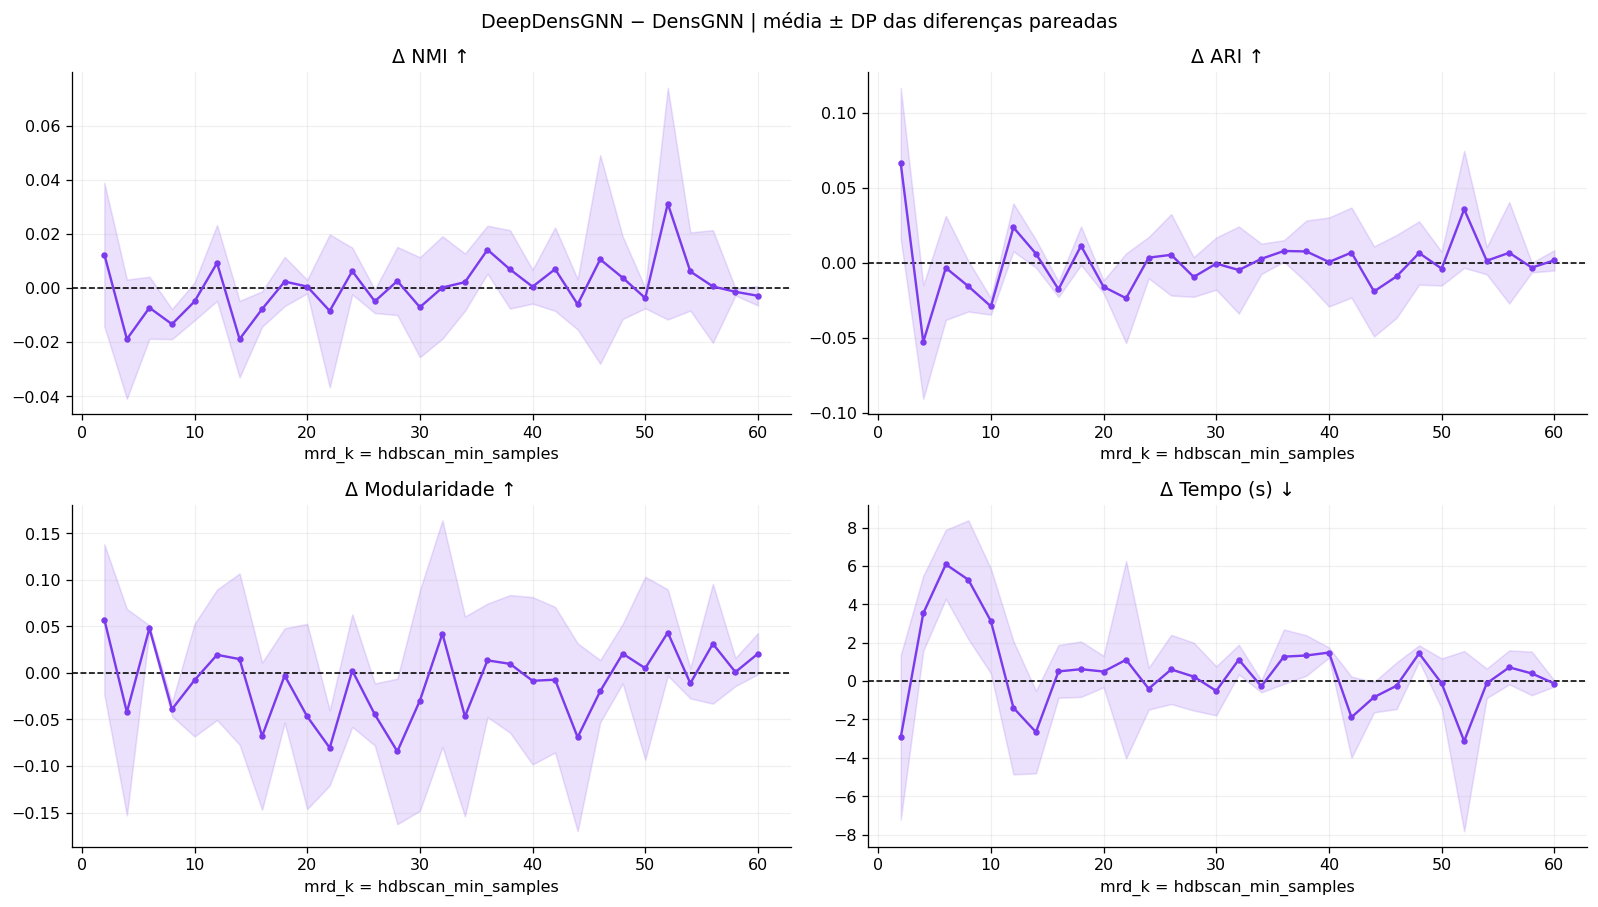

In [18]:
pair_keys = ['run_id', 'mrd_k', 'seed']
paired = data[data.model == 'densgnn'][pair_keys + METRICS].merge(
    data[data.model == 'deep_densgnn'][pair_keys + METRICS], on=pair_keys,
    how='inner', suffixes=('_densgnn', '_deep_densgnn'), validate='one_to_one')
deltas = paired[pair_keys].copy()
for metric in METRICS:
    deltas[metric] = paired[f'{metric}_deep_densgnn'] - paired[f'{metric}_densgnn']
delta_summary = deltas.groupby('mrd_k')[METRICS].agg(['mean', 'std', 'count'])
print(f'{len(paired)} pares completos; {len(data) - 2 * len(paired)} execuções sem par.')
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, metric in zip(axes.flat, ['nmi', 'ari', 'modularity', 'runtime_seconds']):
    stats = delta_summary[metric].reindex(K_VALUES)
    mean, std = stats['mean'].to_numpy(float), stats['std'].to_numpy(float)
    ax.axhline(0, color='black', ls='--', lw=1)
    ax.plot(K_VALUES, mean, '-o', ms=3, color='#7c3aed')
    ax.fill_between(K_VALUES, mean - std, mean + std, color='#7c3aed', alpha=.15)
    ax.set(title=f'Δ {TITLES[metric]}', xlabel='mrd_k = hdbscan_min_samples')
fig.suptitle('DeepDensGNN − DensGNN | média ± DP das diferenças pareadas')
fig.tight_layout()
figures['paired_differences'] = fig
plt.show()

## 6. Melhores valores observados e leitura dos resultados

A classificação usa a maior média por k, com no mínimo duas seeds válidas.
Consulte a cobertura antes de comparar pontos com números de repetições diferentes.
Não há um único “melhor k” independente da métrica escolhida.

In [19]:
rankings = []
for metric in ['nmi', 'ari', 'acc', 'modularity']:
    for model in MODELS:
        candidates = summary_long.query('model == @model and metric == @metric and count >= 2')
        best = candidates.sort_values(['mean', 'mrd_k'], ascending=[False, True]).head(3).copy()
        best['rank'] = range(1, len(best) + 1)
        rankings.append(best)
ranking = pd.concat(rankings, ignore_index=True)
display(ranking[['metric', 'model', 'rank', 'mrd_k', 'mean', 'std', 'count']])

lines = [f'**Retrato da análise:** {len(data)} execuções bem-sucedidas e elegíveis, '
         f'{data.mrd_k.nunique()} valores de k e {data.seed.nunique()} seeds.']
for model in MODELS:
    best = ranking[(ranking.model == model) & (ranking.metric == 'nmi') & (ranking['rank'] == 1)]
    if not best.empty:
        r = best.iloc[0]
        lines.append(f'- **{LABELS[model]}:** maior NMI médio em **k={int(r.mrd_k)}**, '
                     f'**{r["mean"]:.4f} ± {r["std"]:.4f}** (n={int(r["count"])}).')
    means = summary.loc[model, 'nmi']['mean']
    if 2 in means.index and 60 in means.index:
        lines.append(f'  NMI médio de k=2 para k=60: {means.loc[2]:.4f} → {means.loc[60]:.4f} '
                     f'(Δ={means.loc[60] - means.loc[2]:+.4f}; comparação dos extremos, não teste de monotonicidade).')
if not deltas.empty:
    wins, losses, ties = (deltas.nmi > 0).sum(), (deltas.nmi < 0).sum(), (deltas.nmi == 0).sum()
    lines.append(f'- Nos pares com NMI disponível, DeepDensGNN supera DensGNN em {wins}, '
                 f'fica abaixo em {losses} e empata em {ties}. '
                 f'A diferença média descritiva é {deltas.nmi.mean():+.4f}.')
lines.append('\nAs curvas e o DP devem ser lidos em conjunto: diferenças pequenas com apenas três seeds '
             'não sustentam, por si só, uma afirmação de superioridade estatística. '
             'Esta grade mede a variação conjunta de mrd_k e hdbscan_min_samples.')
display(Markdown('\n'.join(lines)))

,metric,model,rank,mrd_k,mean,std,count
0,nmi,densgnn,1,4,0.2865,0.0208,3
1,nmi,densgnn,2,26,0.2863,0.0372,3
2,nmi,densgnn,3,32,0.2860,0.0228,3
3,nmi,deep_densgnn,1,32,0.2862,0.0407,3
4,nmi,deep_densgnn,2,18,0.2859,0.0347,3
5,nmi,deep_densgnn,3,24,0.2847,0.0350,3
6,ari,densgnn,1,32,0.2678,0.0203,3
7,ari,densgnn,2,28,0.2639,0.0470,3
8,ari,densgnn,3,30,0.2606,0.0368,3
9,ari,deep_densgnn,1,32,0.2628,0.0467,3


**Retrato da análise:** 180 execuções bem-sucedidas e elegíveis, 30 valores de k e 3 seeds.
- **DensGNN:** maior NMI médio em **k=4**, **0.2865 ± 0.0208** (n=3).
  NMI médio de k=2 para k=60: 0.2722 → 0.1807 (Δ=-0.0915; comparação dos extremos, não teste de monotonicidade).
- **DeepDensGNN:** maior NMI médio em **k=32**, **0.2862 ± 0.0407** (n=3).
  NMI médio de k=2 para k=60: 0.2845 → 0.1778 (Δ=-0.1068; comparação dos extremos, não teste de monotonicidade).
- Nos pares com NMI disponível, DeepDensGNN supera DensGNN em 36, fica abaixo em 54 e empata em 0. A diferença média descritiva é +0.0004.

As curvas e o DP devem ser lidos em conjunto: diferenças pequenas com apenas três seeds não sustentam, por si só, uma afirmação de superioridade estatística. Esta grade mede a variação conjunta de mrd_k e hdbscan_min_samples.

## 7. Exportação

Esta célula salva tabelas CSV e figuras PNG/PDF em `results/minpts_citeseer/analysis/`.
Os resultados originais dos runs permanecem intactos. Reexecutar atualiza estes arquivos de análise.

In [20]:
EXPORT_DIR.mkdir(parents=True, exist_ok=True)
data.drop(columns=['fixed_params']).to_csv(EXPORT_DIR / 'executions.csv', index=False)
summary_long.to_csv(EXPORT_DIR / 'summary_by_k.csv', index=False)
coverage.to_csv(EXPORT_DIR / 'coverage.csv', index=False)
ranking.to_csv(EXPORT_DIR / 'top_k_by_metric.csv', index=False)
deltas.to_csv(EXPORT_DIR / 'paired_differences.csv', index=False)
global_flat = global_summary.copy()
global_flat.columns = ['_'.join(column) for column in global_flat.columns]
global_flat.to_csv(EXPORT_DIR / 'summary_global.csv')
for name, fig in figures.items():
    fig.savefig(EXPORT_DIR / f'{name}.png', dpi=180, bbox_inches='tight')
    fig.savefig(EXPORT_DIR / f'{name}.pdf', bbox_inches='tight')
print('Tabelas e figuras exportadas para:', EXPORT_DIR)

Tabelas e figuras exportadas para: /home/gmessias/NodeClusteringAlgorithms/results/minpts_citeseer/analysis
